In [49]:
#Import necessary libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score,
    precision_score, recall_score, f1_score, classification_report,
    ConfusionMatrixDisplay
)
from scipy.stats import randint
import joblib

In [50]:
#read the dataset to csv

application_df=pd.read_excel("Application_data.xlsx")
loan_df=pd.read_excel("Loan_performance.xlsx")

#print the shape of each df

print("Shape of application data: ", application_df.shape)
print("Shape of loan_performance data: ", loan_df.shape)

Shape of application data:  (647, 31)
Shape of loan_performance data:  (1285, 2)


/usr/local/lib/python3.13/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


In [51]:
application_df.head()

,customer_id,amount_requested,birth_date,status,residence_rent_or_own,monthly_rent_amount,bank_account_direct_deposit,application_when,loan_duration,payment_ach,...,payment_frequency,home_phone_type,other_phone_type,how_use_money,monthly_income_amount,raw_l2c_score,raw_FICO_telecom,raw_FICO_retail,raw_FICO_bank_card,raw_FICO_money
0,9ece67d6c5,500,1991-08-21,Approved,True,0,True,2010-10-16 14:06:05,3,True,...,Semi-monthly,Mobile,NaN,Other,1560,614,574,600,656,561
1,5c2c402094,500,1990-07-24,Approved,True,0,False,2010-10-17 13:01:53,6,True,...,Bi-weekly,Mobile,NaN,Other,900,708,501,550,651,563
2,e6254cad30,400,1980-09-13,Approved,True,620,True,2010-10-17 19:52:34,6,True,...,Bi-weekly,Mobile,NaN,Other,1434,687,522,561,661,598
3,49fb42f51d,500,1976-09-10,Approved,False,785,False,2010-10-18 07:05:00,4,True,...,Bi-weekly,Mobile,NaN,Other,1600,616,560,552,634,591
4,195fbe5739,300,1979-12-01,Approved,True,700,True,2010-10-19 10:58:40,4,True,...,Bi-weekly,Mobile,Home,Other,1360,681,603,654,659,636


In [52]:
loan_df.head()

,idLoan,flgGood
0,0DBA6B011D-01,Bad
1,96ACBBA7ED-01,Bad
2,289421D82A-01,Bad
3,9ECE67D6C5-01,Good
4,5C2C402094-01,Bad


In [53]:
application_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 647 entries, 0 to 646
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   customer_id                  647 non-null    object        
 1   amount_requested             647 non-null    int64         
 2   birth_date                   647 non-null    datetime64[ns]
 3   status                       647 non-null    object        
 4   residence_rent_or_own        647 non-null    bool          
 5   monthly_rent_amount          647 non-null    int64         
 6   bank_account_direct_deposit  647 non-null    bool          
 7   application_when             647 non-null    datetime64[ns]
 8   loan_duration                647 non-null    int64         
 9   payment_ach                  647 non-null    bool          
 10  num_payments                 647 non-null    int64         
 11  payment_amount               647 non-null    

In [54]:
loan_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1285 entries, 0 to 1284
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   idLoan   1285 non-null   object
 1   flgGood  1285 non-null   object
dtypes: object(2)
memory usage: 20.2+ KB


In [55]:

loan_df["customer_id"] = loan_df["idLoan"].str.split("-").str[0].str.lower()

# Perform the inner merge
df = application_df.merge(loan_df, on="customer_id", how="inner")
df["is_good"] = (df["flgGood"] == "Good").astype(int)

print(df.shape)
print(df["is_good"].value_counts(normalize=True))

(650, 34)
is_good
0    0.543077
1    0.456923
Name: proportion, dtype: float64


In [56]:
#check the total null values

df.isnull().sum()

,0
customer_id,0
amount_requested,0
birth_date,0
status,0
residence_rent_or_own,0
monthly_rent_amount,0
bank_account_direct_deposit,0
application_when,0
loan_duration,0
payment_ach,0


In [57]:
print(df.describe().T)
print("The total duplicate ids", df.duplicated("idLoan").sum())

                         count                           mean  \
amount_requested         650.0                     596.538462   
birth_date                 650  1968-07-10 05:27:52.615384616   
monthly_rent_amount      650.0                     585.784615   
application_when           650  2011-02-05 21:08:33.884615424   
loan_duration            650.0                       5.924615   
num_payments             650.0                      10.272308   
payment_amount           650.0                     116.361031   
amount_approved          650.0                     524.307692   
duration_approved        650.0                       5.538462   
payment_amount_approved  628.0                     112.943742   
address_zip              650.0                   81620.398462   
bank_routing_number      650.0               182726578.970769   
monthly_income_amount    650.0                    2614.718462   
raw_l2c_score            650.0                     593.386154   
raw_FICO_telecom         

In [58]:
df["age"] = (df["application_when"] - df["birth_date"]).dt.days / 365.25

income = df["monthly_income_amount"].replace(0, np.nan)
df["loan_to_income"] = df["amount_approved"] / income
df["payment_to_income"] = df["payment_amount"] / income
df["rent_to_income"] = df["monthly_rent_amount"] / income

df["other_phone_type"] = df["other_phone_type"].fillna("None")

In [59]:

df["payment_amount_approved"] = df["payment_amount_approved"].fillna(df["payment_amount"])


df["how_use_money"] = df["how_use_money"].fillna("Unknown")
df["bank_account_duration"] = df["bank_account_duration"].fillna("Unknown")


print(df.isnull().sum())

customer_id                    0
amount_requested               0
birth_date                     0
status                         0
residence_rent_or_own          0
monthly_rent_amount            0
bank_account_direct_deposit    0
application_when               0
loan_duration                  0
payment_ach                    0
num_payments                   0
payment_amount                 0
amount_approved                0
duration_approved              0
payment_amount_approved        0
address_zip                    0
email                          0
bank_routing_number            0
email_duration                 0
residence_duration             0
bank_account_duration          0
payment_frequency              0
home_phone_type                0
other_phone_type               0
how_use_money                  0
monthly_income_amount          0
raw_l2c_score                  0
raw_FICO_telecom               0
raw_FICO_retail                0
raw_FICO_bank_card             0
raw_FICO_m

In [60]:
#creating useful fetures

df["age"] = (df["application_when"] - df["birth_date"]).dt.days / 365.25

income = df["monthly_income_amount"].replace(0, np.nan)
df["loan_to_income"] = df["amount_approved"] / income
df["payment_to_income"] = df["payment_amount"] / income
df["rent_to_income"] = df["monthly_rent_amount"] / income



flgGood
Bad     353
Good    297
Name: count, dtype: int64


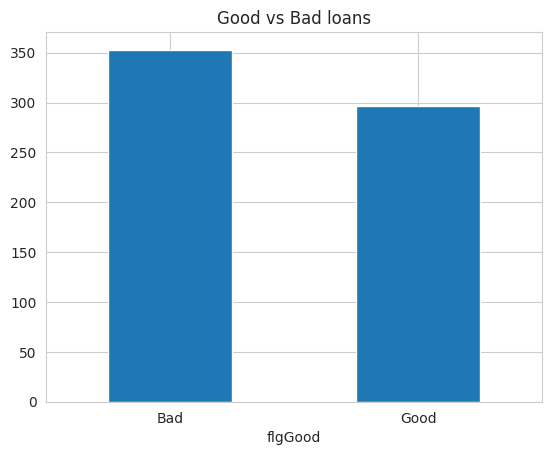

In [61]:
#EDA

sns.set_style("whitegrid")

print(df["flgGood"].value_counts())
df["flgGood"].value_counts().plot(kind="bar", title="Good vs Bad loans", rot=0)
plt.show()

raw_l2c_score         0.529
raw_FICO_telecom      0.601
raw_FICO_money        0.613
raw_FICO_retail       0.616
raw_FICO_bank_card    0.616
dtype: float64


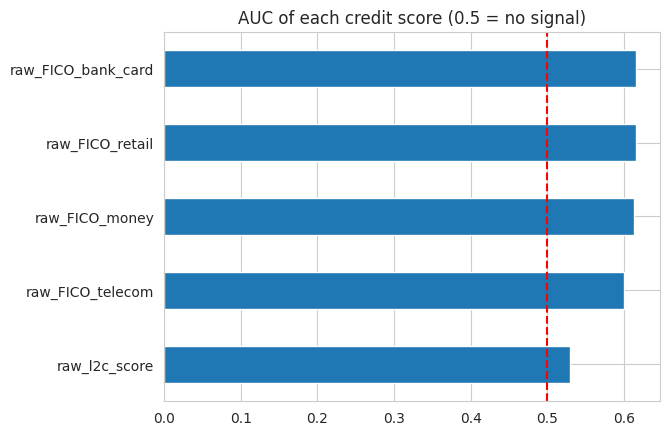

In [62]:
#Which sperates good from bad
score_cols = [c for c in df.columns if c.startswith("raw_")]

auc = {c: roc_auc_score(df["is_good"], df[c]) for c in score_cols}
auc = pd.Series(auc).sort_values()
print(auc.round(3))

auc.plot(kind="barh", title="AUC of each credit score (0.5 = no signal)")
plt.axvline(0.5, color="red", linestyle="--")
plt.show()

                        mean  count
residence_rent_or_own              
False                  0.523    214
True                   0.424    436 

                              mean  count
bank_account_direct_deposit              
False                        0.383    120
True                         0.474    530 

              mean  count
payment_ach              
False        0.000      1
True         0.458    649 

                    mean  count
payment_frequency              
Bi-weekly          0.370    330
Monthly            0.568    176
Semi-monthly       0.595    116
Weekly             0.214     28 

                                 mean  count
how_use_money                               
Bills                           0.355     62
Bills (Auto)                    0.408     49
Bills (General)                 0.529     85
Bills (Home / Utilities)        0.438     16
Bills (Medical)                 0.452     31
Car                             0.448     29
Gifts / Leisure         

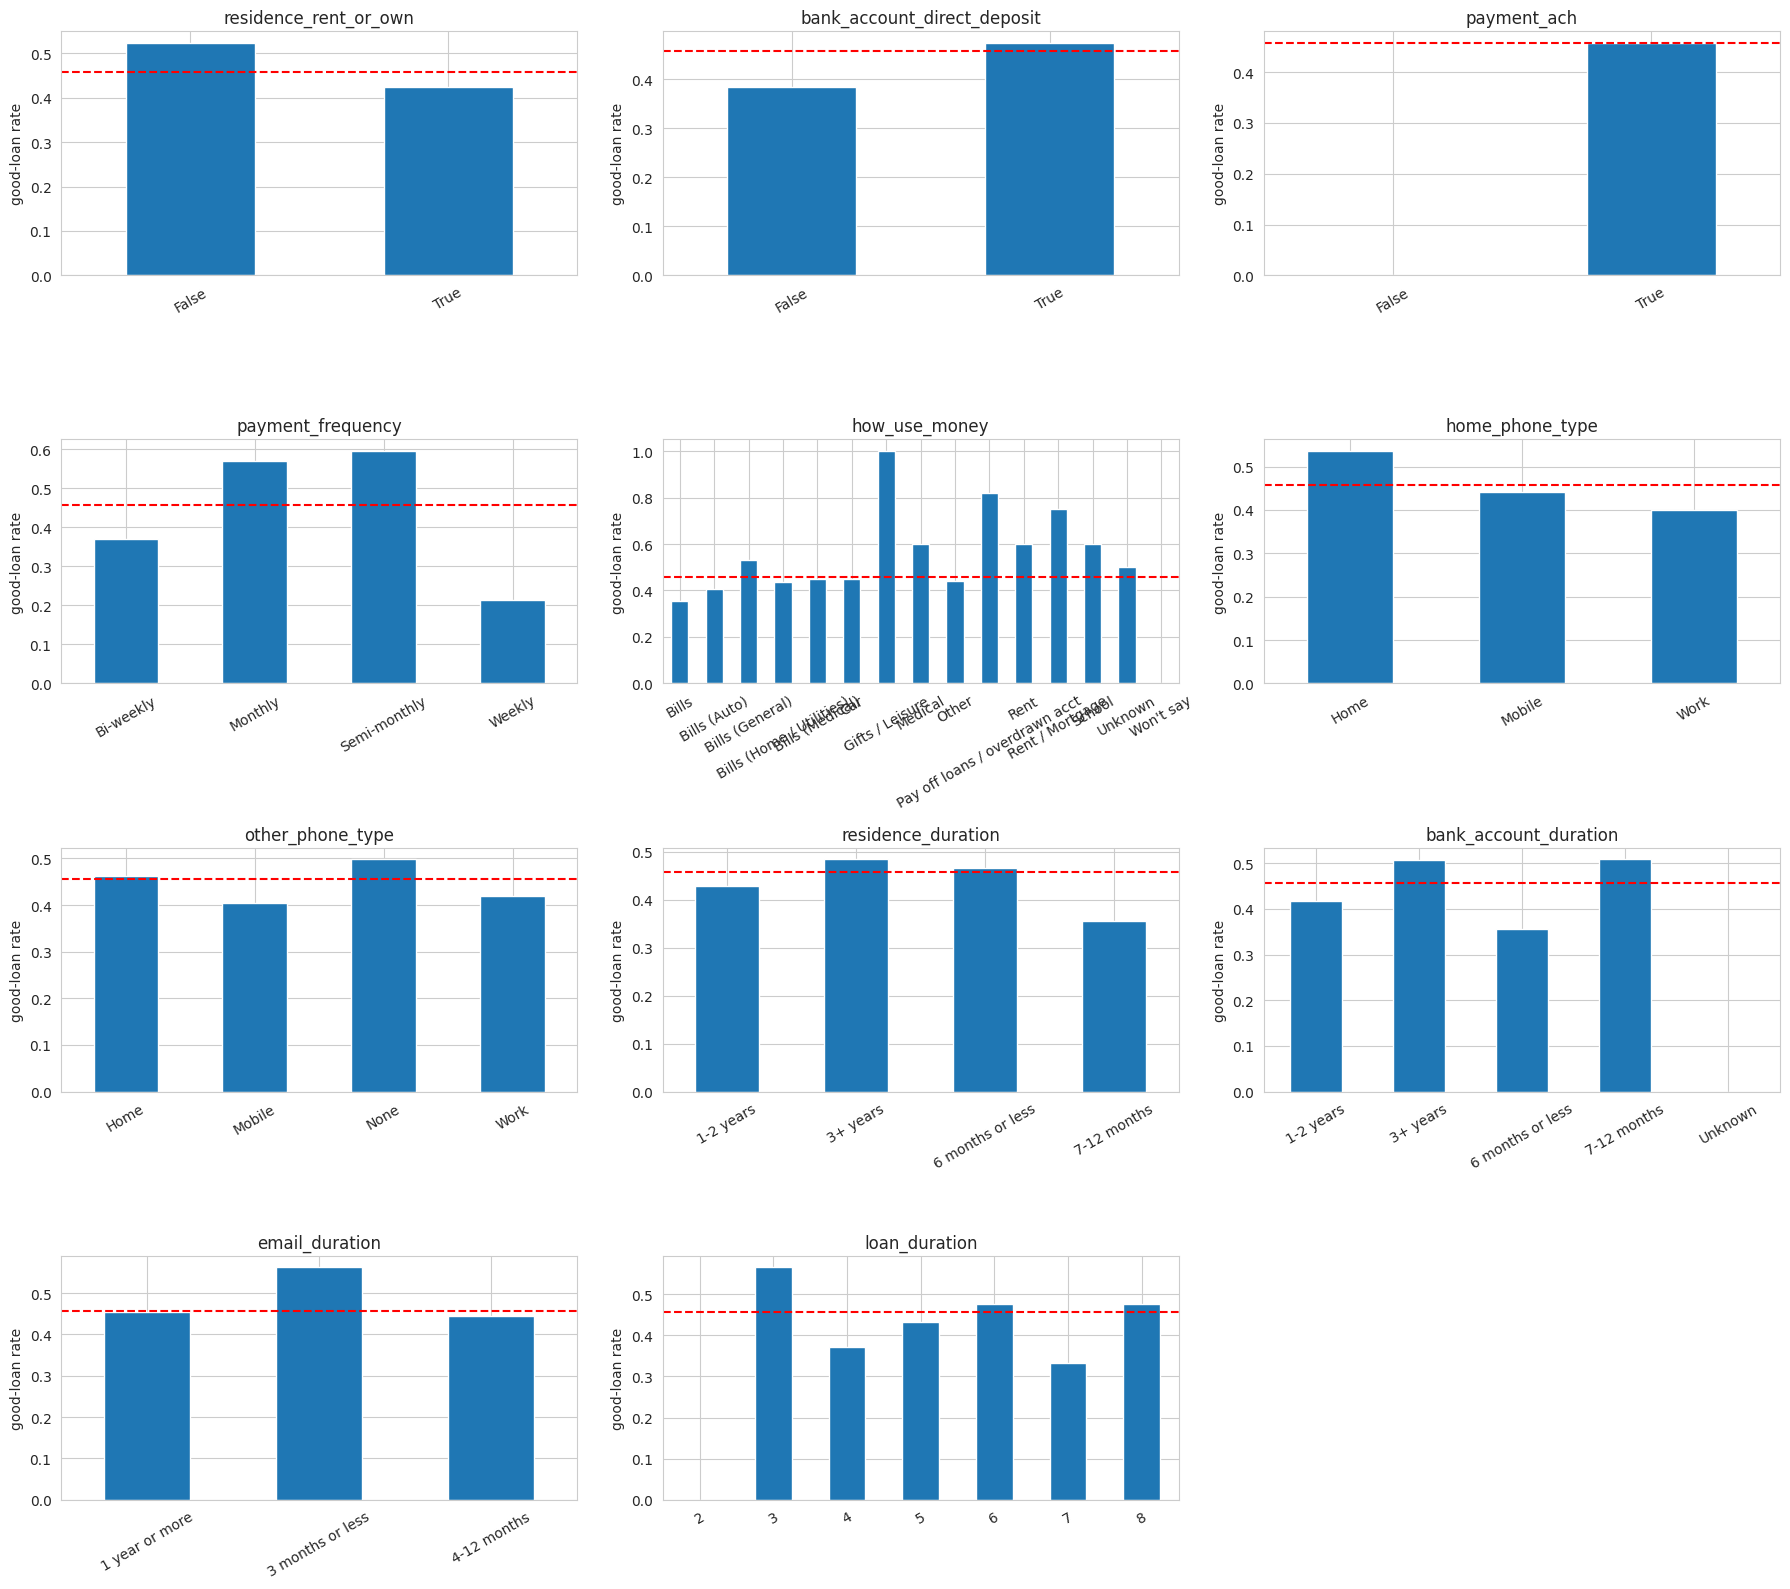

In [63]:
#Good loan rate by category
cat_cols = ["residence_rent_or_own", "bank_account_direct_deposit", "payment_ach",
            "payment_frequency", "how_use_money", "home_phone_type", "other_phone_type",
            "residence_duration", "bank_account_duration", "email_duration", "loan_duration"]

baseline = df["is_good"].mean()

for c in cat_cols:
    summary = df.groupby(c)["is_good"].agg(["mean", "count"]).round(3)
    print(summary, "\n")

fig, axes = plt.subplots(4, 3, figsize=(18, 16))
for ax, c in zip(axes.flat, cat_cols):
    df.groupby(c)["is_good"].mean().plot(kind="bar", ax=ax, title=c, rot=30)
    ax.axhline(baseline, color="red", linestyle="--")   # red line = overall average
    ax.set_ylabel("good-loan rate")
    ax.set_xlabel("")
for ax in axes.flat[len(cat_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

flgGood                    Bad     Good
age                      40.18    43.86
monthly_income_amount  2200.00  2400.00
amount_approved         500.00   500.00
monthly_rent_amount     550.00   529.00
loan_to_income            0.23     0.22
payment_to_income         0.04     0.05
rent_to_income            0.23     0.25
raw_l2c_score           586.00   596.00
raw_FICO_telecom        561.00   577.00
raw_FICO_retail         585.00   609.00
raw_FICO_bank_card      666.00   680.00
raw_FICO_money          601.00   610.00


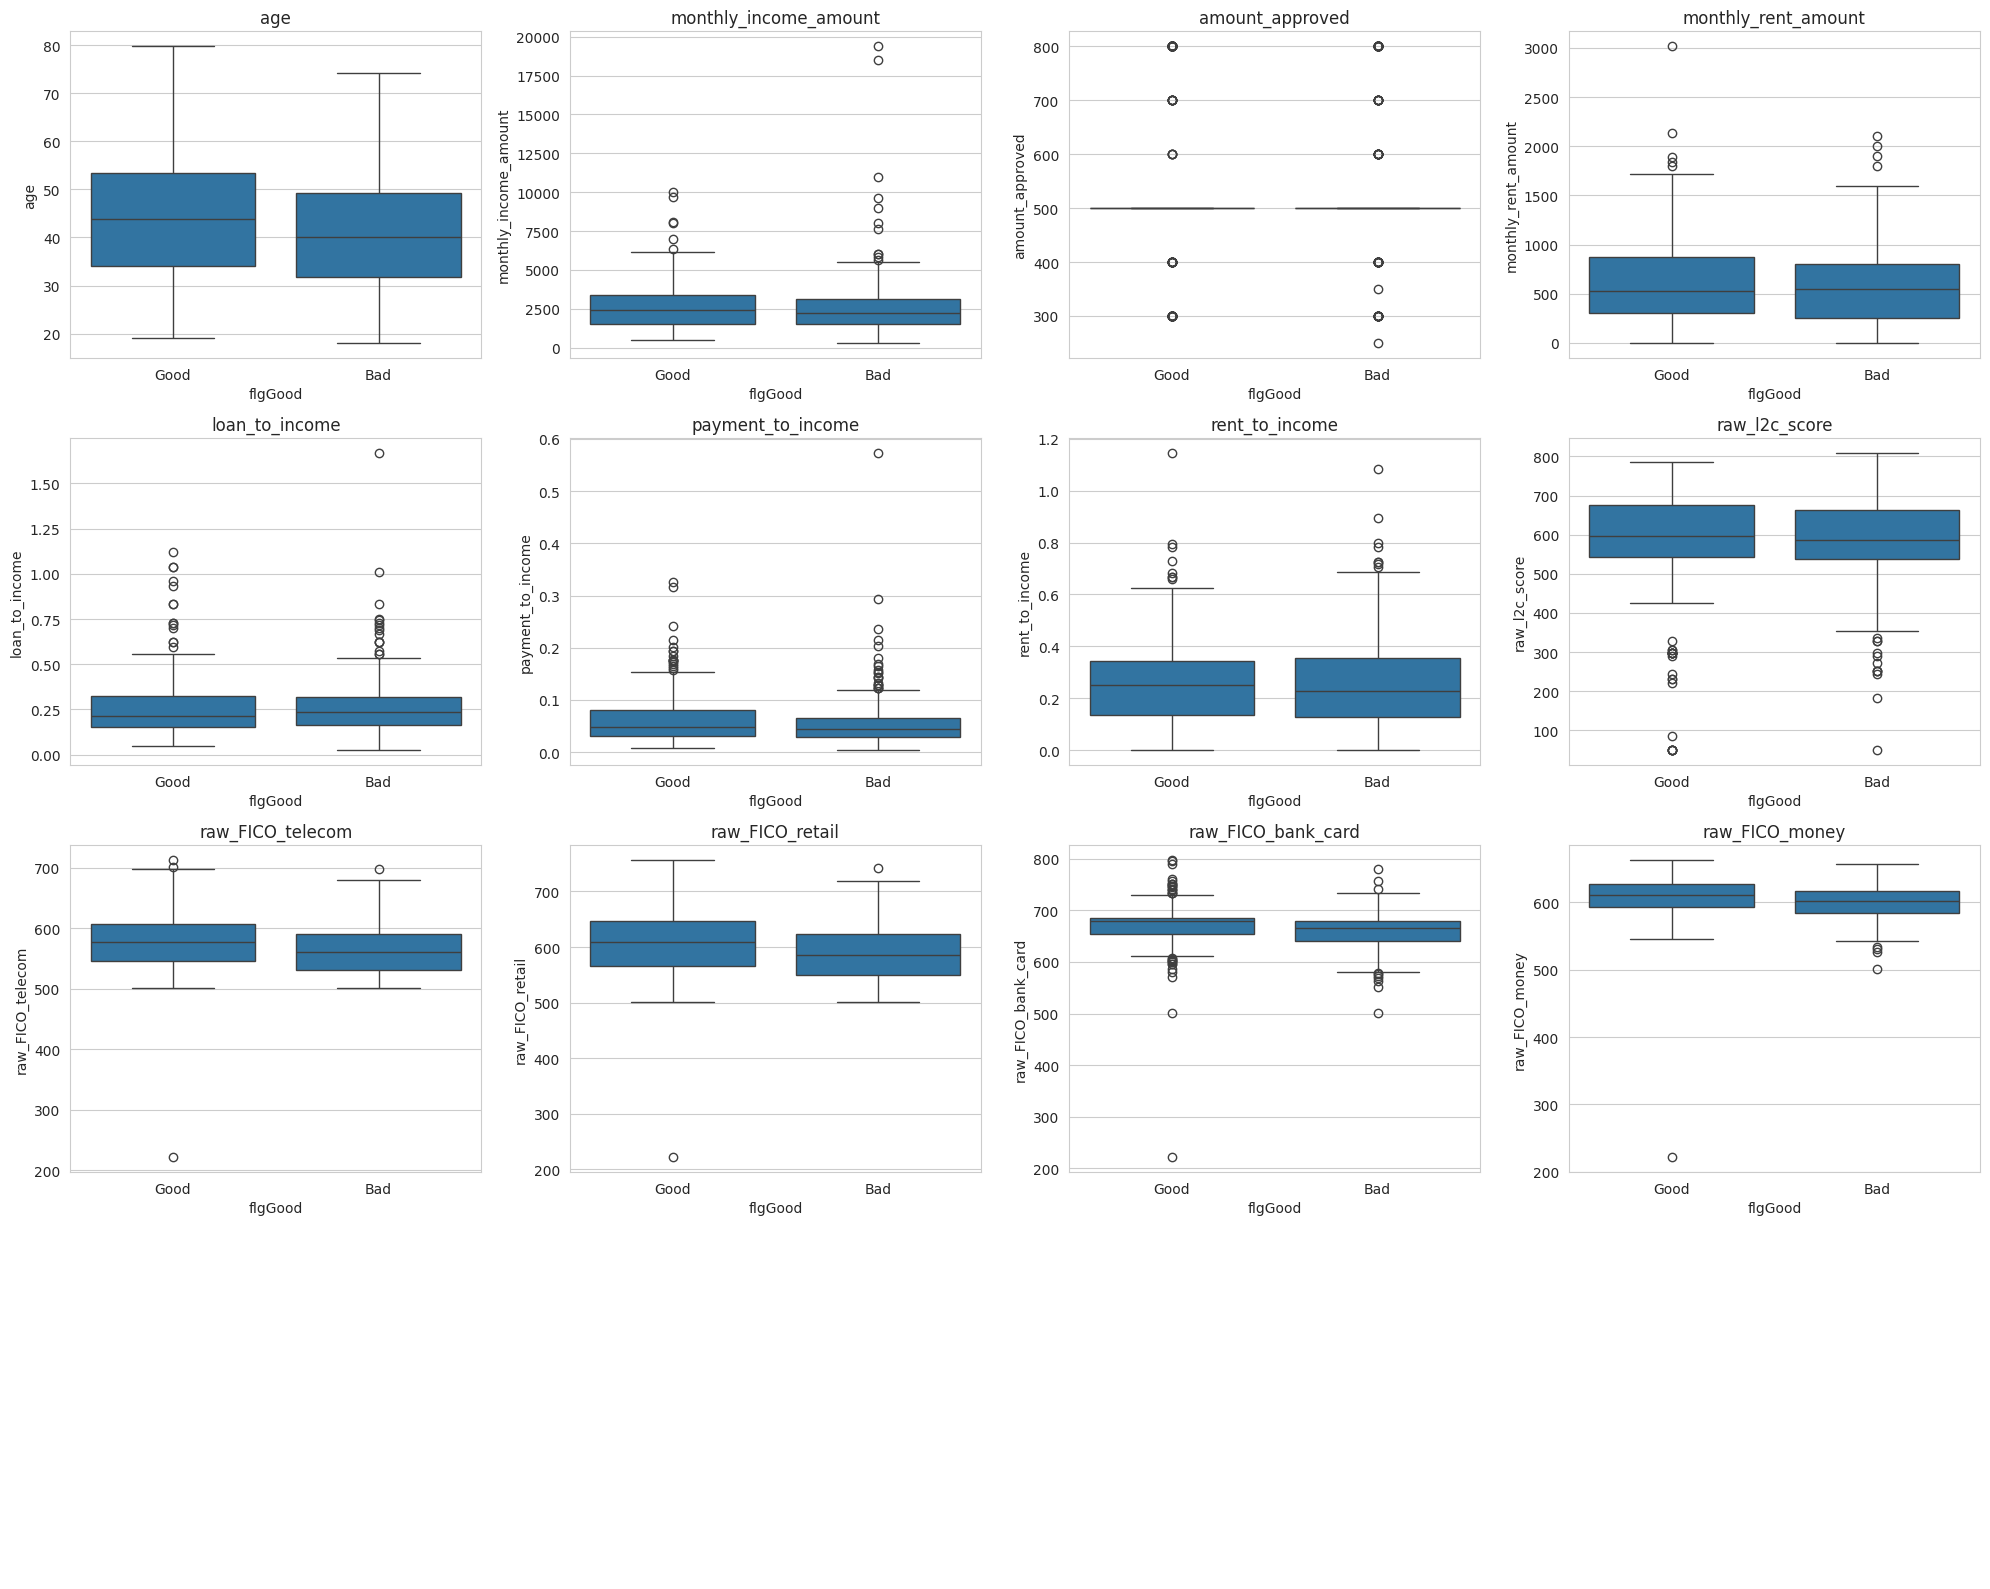

In [64]:
#numerical features
num_cols = ["age", "monthly_income_amount", "amount_approved", "monthly_rent_amount",
            "loan_to_income", "payment_to_income", "rent_to_income"] + score_cols

print(df.groupby("flgGood")[num_cols].median().T.round(2))

fig, axes = plt.subplots(4, 4, figsize=(20, 16))
for ax, c in zip(axes.flat, num_cols):
    sns.boxplot(data=df, x="flgGood", y=c, ax=ax)
    ax.set_title(c)
for ax in axes.flat[len(num_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

                        mean  count
monthly_income_amount              
(299.999, 1500.0]      0.476    164
(1500.0, 2294.5]       0.391    161
(2294.5, 3200.0]       0.452    166
(3200.0, 19392.0]      0.509    159 



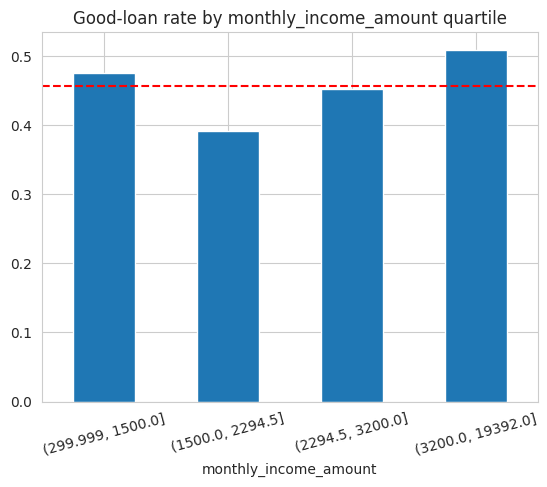

                               mean  count
age                                       
(18.073999999999998, 32.745]  0.399    163
(32.745, 41.537]              0.414    162
(41.537, 51.33]               0.451    162
(51.33, 79.778]               0.564    163 



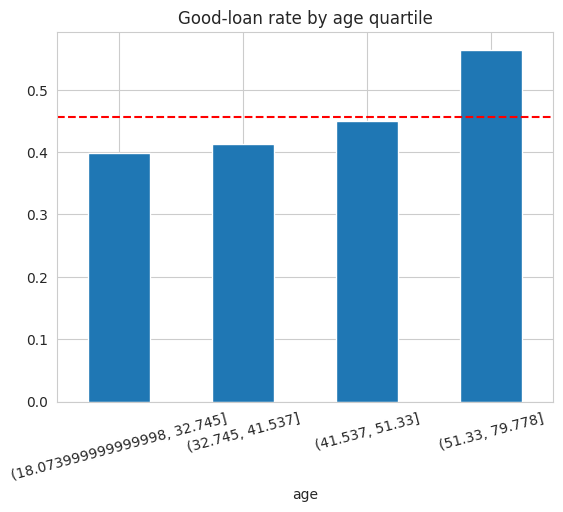

                  mean  count
raw_l2c_score                
(49.999, 539.0]  0.415    164
(539.0, 589.0]   0.418    165
(589.0, 668.75]  0.494    158
(668.75, 808.0]  0.503    163 



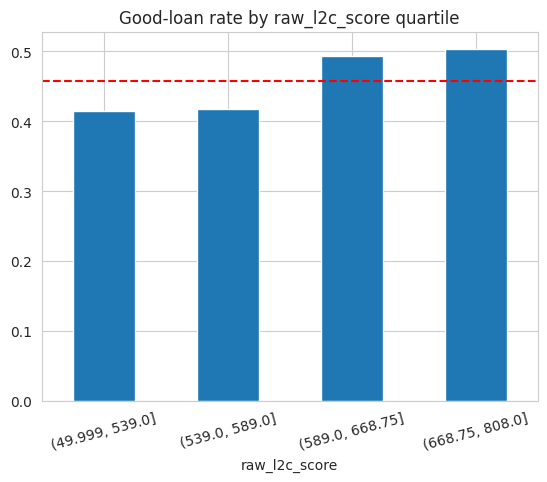

In [65]:
#bands
for col in ["monthly_income_amount", "age", "raw_l2c_score"]:
    bands = pd.qcut(df[col], 4, duplicates="drop")
    print(df.groupby(bands, observed=True)["is_good"].agg(["mean", "count"]).round(3), "\n")
    df.groupby(bands, observed=True)["is_good"].mean().plot(
        kind="bar", title=f"Good-loan rate by {col} quartile", rot=15)
    plt.axhline(baseline, color="red", linestyle="--")
    plt.show()

raw_l2c_score           -0.017
loan_to_income          -0.001
monthly_income_amount    0.014
amount_approved          0.023
rent_to_income           0.027
monthly_rent_amount      0.035
payment_to_income        0.079
age                      0.143
raw_FICO_money           0.152
raw_FICO_bank_card       0.153
raw_FICO_telecom         0.157
raw_FICO_retail          0.181
Name: is_good, dtype: float64


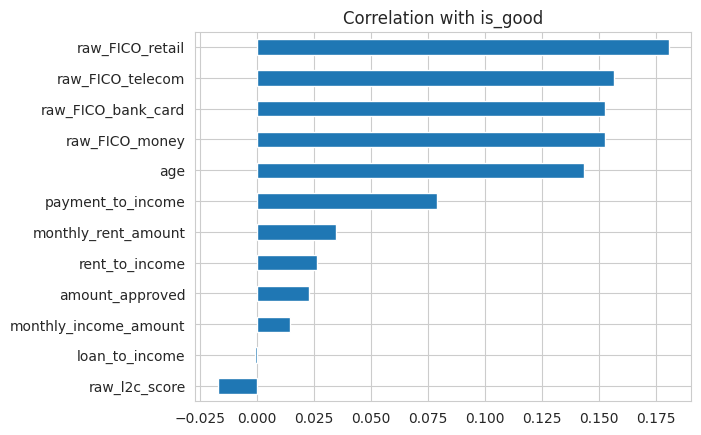

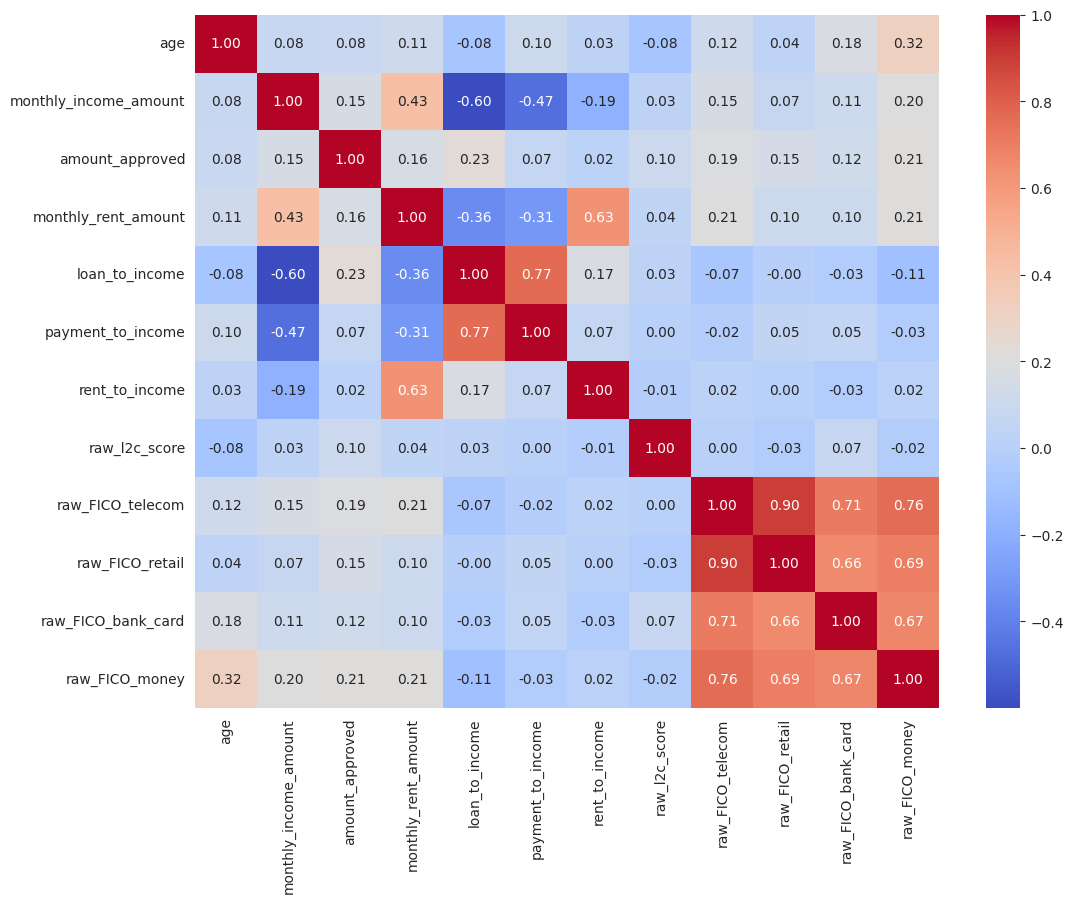

In [66]:
#corelation with target
corr = df[num_cols + ["is_good"]].corr()["is_good"].drop("is_good").sort_values()
print(corr.round(3))
corr.plot(kind="barh", title="Correlation with is_good")
plt.show()

plt.figure(figsize=(12, 9))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

          mean  count
month                
2010-10  0.389     18
2010-11  0.362     58
2010-12  0.472     89
2011-01  0.391    110
2011-02  0.435    131
2011-03  0.530    149
2011-04  0.505     95


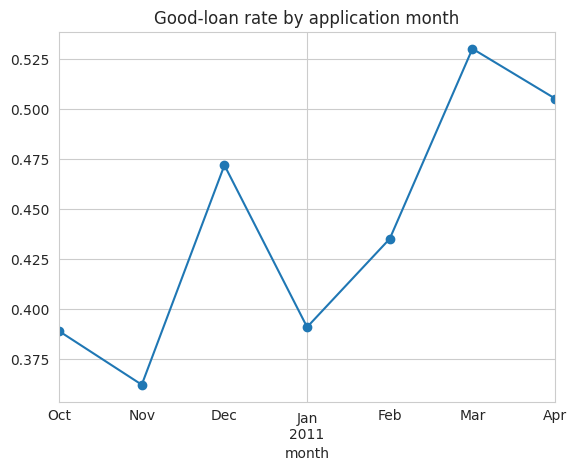

In [67]:
#change in performance over time
df["month"] = df["application_when"].dt.to_period("M")
print(df.groupby("month")["is_good"].agg(["mean", "count"]).round(3))
df.groupby("month")["is_good"].mean().plot(marker="o", title="Good-loan rate by application month")
plt.show()

In [68]:
#prepare the model data

drop_cols = ["customer_id", "idLoan", "flgGood", "is_good", "birth_date",
             "application_when", "email", "bank_routing_number", "address_zip",
             "status", "month"]

X = pd.get_dummies(df.drop(columns=drop_cols), drop_first=True).astype(float)
X = X.fillna(X.median())
y = df["is_good"]

print(X.shape)
print(X.isnull().sum().sum())

(650, 52)
0


,Model,ROC-AUC,Average Precision,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.6833,0.6892,0.6154,0.5843,0.8000,0.6753
1,Random Forest,0.6690,0.6317,0.6231,0.6333,0.5846,0.6080
2,Extra Trees,0.6250,0.6146,0.5615,0.5667,0.5231,0.5440


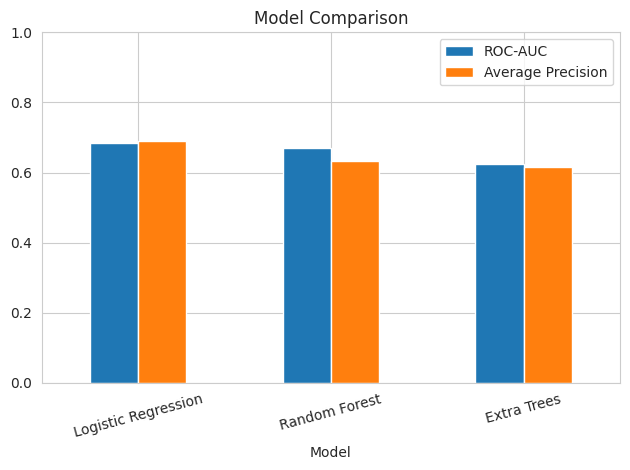

Best CV ROC-AUC: 0.6318
Best Parameters: {'model__max_depth': 8, 'model__max_features': 'log2', 'model__min_samples_leaf': 4, 'model__min_samples_split': 3, 'model__n_estimators': 401}
Test ROC-AUC: 0.6563
Test Average Precision: 0.6382
              precision    recall  f1-score   support

    Bad Loan       0.60      0.49      0.54        65
   Good Loan       0.57      0.68      0.62        65

    accuracy                           0.58       130
   macro avg       0.59      0.58      0.58       130
weighted avg       0.59      0.58      0.58       130



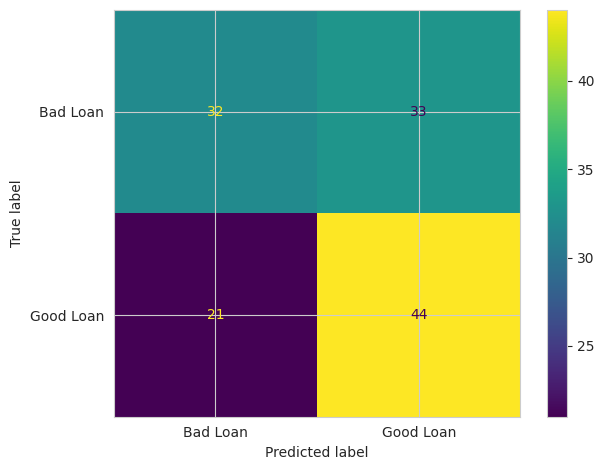

,Feature,Importance
33,cat__payment_frequency_Bi-weekly,0.062806
35,cat__payment_frequency_Semi-monthly,0.058653
27,cat__residence_duration_7-12 months,0.040615
14,num__raw_FICO_retail,0.038848
0,num__amount_requested,0.035675
36,cat__payment_frequency_Weekly,0.035537
34,cat__payment_frequency_Monthly,0.035230
29,cat__bank_account_duration_3+ years,0.033710
1,num__residence_rent_or_own,0.032889
16,num__raw_FICO_money,0.028375


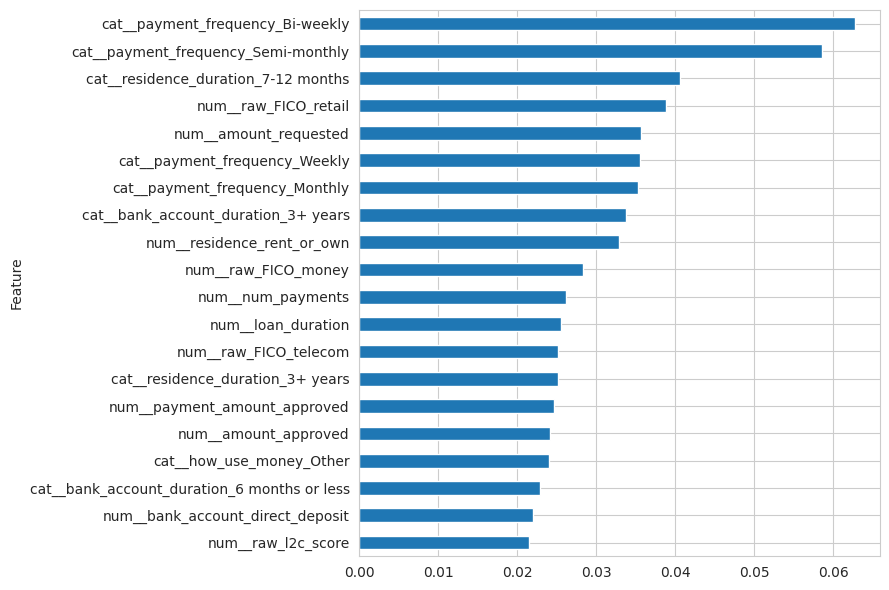

Pipeline saved successfully.


In [69]:
target = "is_good"

exclude_cols = [
    "customer_id", "idLoan", "flgGood", target, "birth_date",
    "application_when", "email", "bank_routing_number",
    "address_zip", "status", "month"
]

X_model = df.drop(columns=exclude_cols, errors="ignore").copy()
y_model = df[target]

valid = y_model.notna()
X_model = X_model.loc[valid]
y_model = y_model.loc[valid].astype(int)

if "application_when" in df.columns and df.loc[X_model.index, "application_when"].notna().all():
    order = df.loc[X_model.index, "application_when"].sort_values(kind="stable").index
    split_at = int(len(order) * 0.8)
    train_idx, test_idx = order[:split_at], order[split_at:]
    X_train, X_test = X_model.loc[train_idx], X_model.loc[test_idx]
    y_train, y_test = y_model.loc[train_idx], y_model.loc[test_idx]
else:
    X_train, X_test, y_train, y_test = train_test_split(
        X_model, y_model, test_size=0.2, stratify=y_model, random_state=42
    )

num_cols = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=["number", "bool"]).columns.tolist()

def make_pipeline(model, scale=False):
    num_steps = [("imputer", SimpleImputer(strategy="median"))]

    if scale:
        num_steps.append(("scaler", StandardScaler()))

    preprocessor = ColumnTransformer([
        ("num", Pipeline(num_steps), num_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), cat_cols)
    ])

    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

models = {
    "Logistic Regression": make_pipeline(
        LogisticRegression(max_iter=2000, class_weight="balanced"), scale=True
    ),
    "Random Forest": make_pipeline(
        RandomForestClassifier(
            n_estimators=300, class_weight="balanced",
            random_state=42, n_jobs=1
        )
    ),
    "Extra Trees": make_pipeline(
        ExtraTreesClassifier(
            n_estimators=300, class_weight="balanced",
            random_state=42, n_jobs=1
        )
    )
}

results = []
fitted_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    fitted_models[name] = model

    prob = model.predict_proba(X_test)[:, 1]
    pred = (prob >= 0.5).astype(int)

    results.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_test, prob),
        "Average Precision": average_precision_score(y_test, prob),
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values("ROC-AUC", ascending=False)
display(results_df.round(4))

results_df.set_index("Model")[["ROC-AUC", "Average Precision"]].plot(
    kind="bar", ylim=(0, 1), rot=15, title="Model Comparison"
)
plt.tight_layout()
plt.show()

pipeline = make_pipeline(
    ExtraTreesClassifier(class_weight="balanced", random_state=42, n_jobs=1)
)

params = {
    "model__n_estimators": randint(200, 601),
    "model__max_depth": [None, 8, 12, 16, 24, 32],
    "model__min_samples_split": randint(2, 16),
    "model__min_samples_leaf": randint(1, 9),
    "model__max_features": ["sqrt", "log2", 0.5, 0.8]
}

search = RandomizedSearchCV(
    pipeline,
    param_distributions=params,
    n_iter=20,
    scoring="roc_auc",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    random_state=42,
    n_jobs=-1,
    refit=True
)

search.fit(X_train, y_train)
best_model = search.best_estimator_

print("Best CV ROC-AUC:", round(search.best_score_, 4))
print("Best Parameters:", search.best_params_)

prob = best_model.predict_proba(X_test)[:, 1]
pred = (prob >= 0.5).astype(int)

print("Test ROC-AUC:", round(roc_auc_score(y_test, prob), 4))
print("Test Average Precision:", round(average_precision_score(y_test, prob), 4))
print(classification_report(
    y_test, pred, target_names=["Bad Loan", "Good Loan"], zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=["Bad Loan", "Good Loan"]
)
plt.tight_layout()
plt.show()

feature_names = best_model.named_steps[
    "preprocessor"
].get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": best_model.named_steps["model"].feature_importances_
}).sort_values("Importance", ascending=False).head(20)

display(importance_df)

importance_df.sort_values("Importance").plot(
    x="Feature", y="Importance", kind="barh",
    legend=False, figsize=(9, 6)
)
plt.tight_layout()
plt.show()

joblib.dump(best_model, "taplend_loan_pipeline.joblib")
print("Pipeline saved successfully.")


In [ ]:
new_predictions = best_model.predict(X_new)
new_probabilities = best_model.predict_proba(X_new)[:, 1]